<a href="https://colab.research.google.com/github/AdityaJare/ML-PRojects/blob/main/star_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install keras-tuner xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 4.8 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt
from xgboost import XGBClassifier

In [4]:
df = pd.read_csv("/content/star_classification.csv")

In [5]:
df.shape

(25036, 18)

In [7]:
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812.0,56354.0,171.0
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445.0,58158.0,427.0
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576.0,55592.0,299.0
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149.0,58039.0,775.0
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121.0,56187.0,842.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25036 entries, 0 to 25035
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   obj_ID       25036 non-null  float64
 1   alpha        25036 non-null  float64
 2   delta        25036 non-null  float64
 3   u            25036 non-null  float64
 4   g            25036 non-null  float64
 5   r            25036 non-null  float64
 6   i            25036 non-null  float64
 7   z            25036 non-null  float64
 8   run_ID       25036 non-null  int64  
 9   rerun_ID     25036 non-null  int64  
 10  cam_col      25036 non-null  int64  
 11  field_ID     25036 non-null  int64  
 12  spec_obj_ID  25036 non-null  float64
 13  class        25036 non-null  object 
 14  redshift     25036 non-null  float64
 15  plate        25035 non-null  float64
 16  MJD          25035 non-null  float64
 17  fiber_ID     25035 non-null  float64
dtypes: float64(13), int64(4), object(1)
memory usa

In [9]:
df.describe()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,2.503600e+04,25036.000000,25036.000000,25036.000000,25036.000000,25036.000000,25036.000000,25036.000000,25036.000000,25036.0,25036.000000,25036.000000,2.503600e+04,25036.000000,25035.000000,25035.000000,25035.000000
mean,1.237665e+18,176.255796,22.956986,22.039444,20.607352,19.646687,19.102279,18.794076,4543.397508,301.0,3.529557,190.239216,5.737556e+18,0.584174,5095.780268,55562.088316,450.434871
std,8.645068e+12,98.904982,19.303280,2.232959,2.026547,1.852814,1.764698,1.780949,2012.860519,0.0,1.582801,149.409020,3.321437e+18,0.748126,2950.044298,1813.885844,268.110290
min,1.237646e+18,0.005528,-16.847136,12.262400,10.511390,9.822070,9.469903,9.612333,109.000000,301.0,1.000000,11.000000,2.995793e+17,-0.006863,266.000000,51608.000000,1.000000
25%,1.237659e+18,124.315625,3.591892,20.335857,18.987208,18.154455,17.755607,17.485298,3225.000000,301.0,2.000000,84.000000,2.792054e+18,0.047303,2479.500000,54208.000000,230.000000
50%,1.237664e+18,176.527345,21.588670,22.103460,21.043080,20.116100,19.428635,19.033805,4263.000000,301.0,4.000000,153.000000,5.595931e+18,0.407231,4970.000000,55863.000000,437.000000
75%,1.237671e+18,235.581623,38.004914,23.628197,22.091387,21.036070,20.425545,19.957375,5933.000000,301.0,5.000000,246.000000,8.310312e+18,0.719575,7381.000000,56753.000000,639.000000
max,1.237681e+18,359.999810,82.764421,30.660390,31.602240,29.374110,30.250090,26.427790,8162.000000,301.0,6.000000,847.000000,1.412685e+19,7.011245,12547.000000,58932.000000,1000.000000


In [10]:
df["class"].value_counts()

,count
class,
GALAXY,14451
STAR,5562
QSO,5023


In [13]:
df.isnull().sum()

,0
obj_ID,0
alpha,0
delta,0
u,0
g,0
r,0
i,0
z,0
run_ID,0
rerun_ID,0


In [14]:
df["plate"].unique()

array([ 5812., 10445.,  4576., ...,  4090.,  9617.,    nan])

In [16]:
bad = (df[["u", "g", "z"]] < -9000).any(axis=1)
print("bad rows removed:", bad.sum())
df = df[~bad].reset_index(drop=True)

bad rows removed: 0


In [17]:
drop_cols = ["obj_ID", "run_ID", "rerun_ID", "cam_col", "field_ID",
             "spec_obj_ID", "plate", "MJD", "fiber_ID", "alpha", "delta"]

In [18]:
df = df.drop(columns=[c for c in drop_cols if c in df.columns])
print("features:", [c for c in df.columns if c != "class"])

features: ['u', 'g', 'r', 'i', 'z', 'redshift']


In [19]:
df.shape

(25036, 7)

In [20]:
df.head()

,u,g,r,i,z,class,redshift
0,23.87882,22.27530,20.39501,19.16573,18.79371,GALAXY,0.634794
1,24.77759,22.83188,22.58444,21.16812,21.61427,GALAXY,0.779136
2,25.26307,22.66389,20.60976,19.34857,18.94827,GALAXY,0.644195
3,22.13682,23.77656,21.61162,20.50454,19.25010,GALAXY,0.932346
4,19.43718,17.58028,16.49747,15.97711,15.54461,GALAXY,0.116123


In [21]:
le = LabelEncoder()
y = le.fit_transform(df["class"])

In [22]:
print("classes:", le.classes_)

classes: ['GALAXY' 'QSO' 'STAR']


In [23]:
X = df.drop(columns="class")

In [24]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [25]:
assert len(x_train) == len(y_train)

In [26]:
scaler = StandardScaler()

x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)


In [27]:
n_features = x_train_s.shape[1]
print("n_features:", n_features)

n_features: 6


In [28]:
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(weights))
print(class_weight_dict)

{0: np.float64(0.5775086505190311), 1: np.float64(1.6615231458437034), 2: np.float64(1.5002247191011235)}


In [29]:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(n_features,)))

    for i in range(hp.Int("num_layers", 1, 3)):
        model.add(layers.Dense(
            units=hp.Int(f"units_{i}", min_value=16, max_value=128, step=16),
            activation=hp.Choice(f"activation_{i}", values=["relu", "tanh"])
        ))
        model.add(layers.Dropout(hp.Float(f"dropout_{i}", 0.0, 0.4, step=0.1)))

    model.add(layers.Dense(3, activation="softmax"))

    lr = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])
    opt_name = hp.Choice("optimizer", values=["adam", "rmsprop", "nadam"])
    optimizer = {
        "adam": keras.optimizers.Adam(learning_rate=lr),
        "rmsprop": keras.optimizers.RMSprop(learning_rate=lr),
        "nadam": keras.optimizers.Nadam(learning_rate=lr),
    }[opt_name]

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


In [30]:
build_model(kt.HyperParameters()).summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163 (652.00 B)

 Trainable params: 163 (652.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=5, mode="max", restore_best_weights=True
)


In [32]:
tuner = kt.RandomSearch(
    build_model,
    objective=kt.Objective("val_accuracy", direction="max"),
    max_trials=10,
    executions_per_trial=1,
    directory="keras_tuner_dir",
    project_name="stellar_ann",
    overwrite=True
)


In [33]:
tuner.search(
    x_train_s, y_train,
    epochs=40,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weight_dict,
    verbose=1
)

Trial 10 Complete [00h 00m 05s]
val_accuracy: 0.9345980882644653

Best val_accuracy So Far: 0.965302050113678
Total elapsed time: 00h 03m 54s


In [34]:
best_hp = tuner.get_best_hyperparameters(1)[0]
print(best_hp.values)

{'num_layers': 3, 'units_0': 48, 'activation_0': 'tanh', 'dropout_0': 0.4, 'learning_rate': 0.001, 'optimizer': 'nadam', 'units_1': 64, 'activation_1': 'relu', 'dropout_1': 0.0, 'units_2': 128, 'activation_2': 'relu', 'dropout_2': 0.0}


In [35]:
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(
    x_train_s, y_train,
    epochs=100,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7553 - loss: 0.5060 - val_accuracy: 0.8660 - val_loss: 0.3394
Epoch 2/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8643 - loss: 0.2886 - val_accuracy: 0.9036 - val_loss: 0.2680
Epoch 3/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9054 - loss: 0.2331 - val_accuracy: 0.9239 - val_loss: 0.2237
Epoch 4/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9245 - loss: 0.1971 - val_accuracy: 0.9358 - val_loss: 0.1961
Epoch 5/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9352 - loss: 0.1775 - val_accuracy: 0.9478 - val_loss: 0.1661
Epoch 6/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9405 - loss: 0.1668 - val_accuracy: 0.9423 - val_loss: 0.1746
Epoch 7/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9462 - loss: 0.1559 - val_accuracy: 0.9366 - val_loss: 0.1770
Epoch 8/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9469 - loss: 0.1534 - val_accu

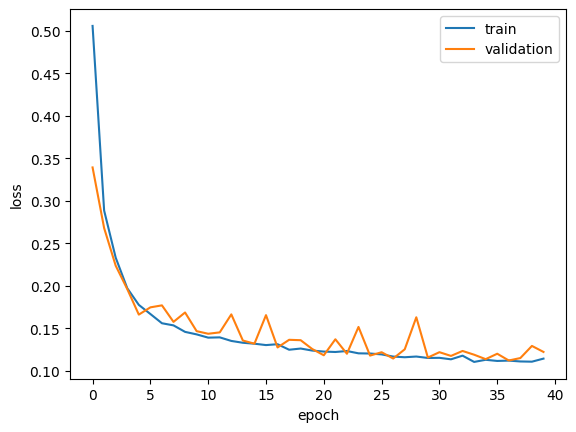

In [36]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

In [37]:
proba = best_model.predict(x_test_s)
y_pred = proba.argmax(axis=1)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


              precision    recall  f1-score   support

      GALAXY       0.98      0.97      0.97      2891
         QSO       0.94      0.95      0.94      1005
        STAR       0.96      1.00      0.98      1112

    accuracy                           0.97      5008
   macro avg       0.96      0.97      0.97      5008
weighted avg       0.97      0.97      0.97      5008



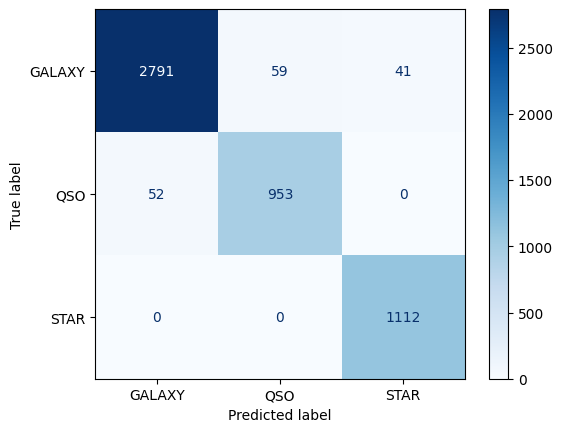

In [38]:
print(classification_report(y_test, y_pred, target_names=le.classes_))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=le.classes_).plot(cmap="Blues")
plt.show()

In [39]:
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    random_state=42, n_jobs=-1)
xgb.fit(x_train_s, y_train)
xgb_pred = xgb.predict(x_test_s)
print(classification_report(y_test, xgb_pred, target_names=le.classes_))

              precision    recall  f1-score   support

      GALAXY       0.98      0.98      0.98      2891
         QSO       0.96      0.94      0.95      1005
        STAR       0.99      1.00      0.99      1112

    accuracy                           0.98      5008
   macro avg       0.98      0.97      0.98      5008
weighted avg       0.98      0.98      0.98      5008



In [40]:
cols_no_z = [c for c in x_train.columns if c != "redshift"]
sc2 = StandardScaler()
xtr2 = sc2.fit_transform(x_train[cols_no_z])
xte2 = sc2.transform(x_test[cols_no_z])


In [41]:
xgb2 = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                     random_state=42, n_jobs=-1).fit(xtr2, y_train)
print("XGBoost WITHOUT redshift:")
print(classification_report(y_test, xgb2.predict(xte2), target_names=le.classes_))

XGBoost WITHOUT redshift:
              precision    recall  f1-score   support

      GALAXY       0.90      0.93      0.92      2891
         QSO       0.81      0.82      0.81      1005
        STAR       0.80      0.73      0.77      1112

    accuracy                           0.86      5008
   macro avg       0.84      0.83      0.83      5008
weighted avg       0.86      0.86      0.86      5008



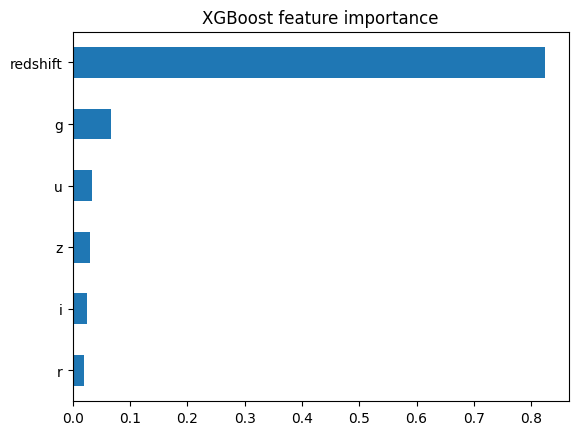

In [42]:
imp = pd.Series(xgb.feature_importances_, index=x_train.columns).sort_values()
imp.plot(kind="barh", title="XGBoost feature importance"); plt.show()